In [1]:
from pathlib import Path

import numpy as np
import lightning as L
import matplotlib.pyplot as plt
import torch
import torchmetrics

from minerva.data.data_modules.base import MinervaDataModule
from minerva.data.datasets.base import SimpleDataset
from minerva.models.nets.image.deeplabv3 import DeepLabV3, DeepLabV3RegressionHead
from minerva.transforms.transform import Repeat, CastTo, Unsqueeze, TransformPipeline

from utils.data import NumpyFolderReader

## Create the Data Module

In [2]:
root_data_dir = Path("../../../../data/processed/seismic_attribute_calculation/F3/partition_method_test_predefined_val_last/")
attribute = "envelope"
seed = 42

In [3]:
###########################
# Train dataset
###########################
train_data_reader = NumpyFolderReader(
    root_data_dir / "train" / "data",
    sort_method=["text"]
)
train_label_reader = NumpyFolderReader(
    root_data_dir / "train" / "attributes" / attribute,
    sort_method=["text"]
)
train_data_transforms = TransformPipeline(
    [
        Unsqueeze(0),
        Repeat(axis=0, n_repetitions=3),
        CastTo("float32"),
    ]
)

train_label_transforms = TransformPipeline(
    [
        CastTo("float32"),
    ]
)

train_dataset = SimpleDataset(
    readers=[train_data_reader, train_label_reader],
    transforms=[train_data_transforms, train_label_transforms],
)

###########################
# Validation dataset
###########################
val_data_reader = NumpyFolderReader(
    root_data_dir / "val" / "data",
    sort_method=["text"],
)
val_label_reader = NumpyFolderReader(
    root_data_dir / "val" / "attributes" / attribute,
    sort_method=["text"]
)
val_data_transforms = TransformPipeline(
    [
        Unsqueeze(0),
        Repeat(axis=0, n_repetitions=3),
        CastTo("float32"),
    ]
)
val_label_transforms = TransformPipeline(
    [
        CastTo("float32"),
    ]
)

val_dataset = SimpleDataset(
    readers=[val_data_reader, val_label_reader],
    transforms=[val_data_transforms, val_label_transforms],
)

###########################
# Test dataset
###########################
test_data_reader = NumpyFolderReader(
    root_data_dir / "test" / "data",
    sort_method=["text"]
)
test_label_reader = NumpyFolderReader(
    root_data_dir / "test" / "attributes" / attribute,
    sort_method=["text"]
)
test_data_transforms = TransformPipeline(
    [Unsqueeze(0), Repeat(axis=0, n_repetitions=3), CastTo("float32")]
)  # Transforms to first reader (data)
test_label_transforms = TransformPipeline([CastTo("float32")])

test_dataset = SimpleDataset(
    readers=[test_data_reader, test_label_reader],
    transforms=[test_data_transforms, test_label_transforms],
)

In [4]:
train_x, train_y = train_dataset[0]
print(f"Train sample shapes: {train_x.shape} (dtype: {train_x.dtype}), Label Shape: {train_y.shape} (dtype: {train_y.dtype})")

val_x, val_y = val_dataset[0]
print(f"Validation sample shapes: {val_x.shape} (dtype: {val_x.dtype}), Label Shape: {val_y.shape} (dtype: {val_y.dtype})")

test_x, test_y = test_dataset[0]
print(f"Test sample shapes: {test_x.shape} (dtype: {test_x.dtype}), Label Shape: {test_y.shape} (dtype: {test_y.dtype})")

Train sample shapes: (3, 255, 701) (dtype: float32), Label Shape: (255, 701) (dtype: float32)
Validation sample shapes: (3, 255, 701) (dtype: float32), Label Shape: (255, 701) (dtype: float32)
Test sample shapes: (3, 255, 701) (dtype: float32), Label Shape: (255, 701) (dtype: float32)


In [5]:
data_module = MinervaDataModule(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    test_dataset=test_dataset,
    batch_size=8,
    num_workers=4,
    additional_train_dataloader_kwargs={"drop_last": True},
    name="F3 Dataset"
)

print(data_module)

                    🆔 F3 Dataset
└── Predict Split: test
📂 Datasets:
   ├── Train Dataset:
   │      ==================================================
   │                 📂 SimpleDataset Information            
   │      ==================================================
   │      📌 Dataset Type: SimpleDataset
   │         └── Reader 0: NumpyFolderReader at '../../../../data/processed/seismic_attribute_calculation/F3/partition_method_test_predefined_val_last/train/data' (351 files)
   │         │     └── Transform: TransformPipeline(transforms=[Unsqueeze(axis=0), Repeat(axis=0, n_repetitions=3), CastTo(dtype=float32)])
   │         └── Reader 1: NumpyFolderReader at '../../../../data/processed/seismic_attribute_calculation/F3/partition_method_test_predefined_val_last/train/attributes/envelope' (351 files)
   │         │     └── Transform: TransformPipeline(transforms=[CastTo(dtype=float32)])
   │         │
   │         └── Total Readers: 2
   │      ==================================

### Plot a sample from the training set

In [6]:
def plot_data_label_slice(data, label, size=(12, 6), show=True):
    fig, axes = plt.subplots(1, 2, figsize=size)

    axes[0].imshow(data, cmap="seismic")
    axes[0].set_title("Seismic Data Slice")

    axes[1].imshow(label, cmap="gray", vmin=0, vmax=np.max(label))
    axes[1].set_title(f"Attribute Slice ({attribute.capitalize()})")
    # axes[1].colorbar = plt.colorbar(axes[1].images[0], ax=axes[1])

    plt.tight_layout()
    if show:
        plt.show()
    return fig

/tmp/ipykernel_2003/4006026116.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


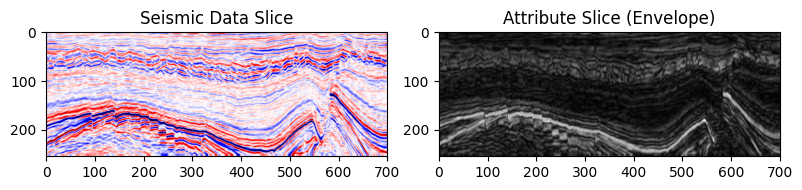

In [7]:
x, y = train_dataset[0]
fig = plot_data_label_slice(x[0,:,:], y, size=(8, 6), show=False)
fig.show()

## Model

In [8]:
class MSEWithSqueeze(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.mse = torch.nn.MSELoss()

    def forward(self, input, target):
        # Squeeze the channel dimension if it exists
        if input.dim() == 4 and input.size(1) == 1:
            input = input.squeeze(1)
        if target.dim() == 4 and target.size(1) == 1:
            target = target.squeeze(1)
        return self.mse(input, target)


model = DeepLabV3(
    num_classes=1,
    loss_fn=MSEWithSqueeze(),
    pred_head=DeepLabV3RegressionHead(in_channels=2048, out_channels=1),
    loss_long=False,
)

model

DeepLabV3(
  (backbone): DeepLabV3Backbone(
    (RN50model): ResNet(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu)

## Trainer

In [9]:
trainer = L.Trainer(
    max_epochs=3,
    logger=False,                   # Disable logging for simplicity
    enable_checkpointing=False,     # Disable checkpointing for simplicity
    accelerator="gpu",
    devices=1,
    limit_train_batches=10,       # Run a fraction of training batches for quick testing
    limit_val_batches=10,         # Run a fraction of validation batches for quick testing
)

trainer

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [10]:
trainer.fit(model, data_module)

You are using a CUDA device ('NVIDIA RTX A6000') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name     ┃ Type                    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone │ DeepLabV3Backbone       │ 25.6 M │ train │     0 │
│ 1 │ fc       │ DeepLabV3RegressionHead │ 16.1 M │ train │     0 │
│ 2 │ loss_fn  │ MSEWithSqueeze          │      0 │ train │     0 │
└───┴──────────┴─────────────────────────┴────────┴───────┴───────┘

Trainable params: 41.7 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 41.7 M                                                                                               
Total estimated model params size (MB): 166                                                                        
Modules in train mode: 187                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/home/vscode/.local/lib/python3.10/site-packages/lightning/pytorch/core/module.py:522: You called 
`self.log('val_loss', ..., logger=True)` but have no logger configured. You can enable one by doing 
`Trainer(logger=ALogger(...))`

/home/vscode/.local/lib/python3.10/site-packages/lightning/pytorch/core/module.py:522: You called 
`self.log('train_loss', ..., logger=True)` but have no logger configured. You can enable one by doing 
`Trainer(logger=ALogger(...))`

`Trainer.fit` stopped: `max_epochs=3` reached.


## Calculate metrics on the test set

In [11]:
# Predict
logits = trainer.predict(model, data_module)  # type: ignore
logits = torch.cat(logits, dim=0)  # type: ignore
predictions = torch.argmax(logits, dim=1).to(model.device)  # Not a problem as task is single-value regression

# Get test labels
test_y = torch.tensor([data_module.test_dataset[i][1] for i in range(len(data_module.test_dataset))]).to(model.device)  # type: ignore

print(
    f"Test y shape: {test_y.shape} (dtype: {test_y.dtype}), Predicted y shape: {predictions.shape} (dtype: {predictions.dtype})"
)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Output()

Test y shape: torch.Size([200, 255, 701]) (dtype: torch.float32), Predicted y shape: torch.Size([200, 255, 701]) (dtype: torch.int64)


/tmp/ipykernel_2003/2348952013.py:7: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:254.)
  test_y = torch.tensor([data_module.test_dataset[i][1] for i in range(len(data_module.test_dataset))]).to(model.device)  # type: ignore


In [12]:
# # Calculcate scores
mse_metric = torchmetrics.MeanSquaredError().to(model.device)
mse = mse_metric(predictions.float(), test_y.float())
print(f"Mean Squared Error (MSE) on Test Set: {mse.item():.4f}")

Mean Squared Error (MSE) on Test Set: 0.1031


### Plot a prediction from the test set

In [13]:
def plot_data_label_prediction_slice(data, label, prediction, size=(24, 6), show=True):
    pred_diff = np.abs(prediction - label)

    fig, axes = plt.subplots(1, 4, figsize=size)

    axes[0].imshow(data, cmap="seismic")
    axes[0].set_title("Seismic Data Slice")

    axes[1].imshow(label, cmap="gray", vmin=0, vmax=np.max(label))
    axes[1].set_title(f"Attribute Label Slice ({attribute.capitalize()})")

    axes[2].imshow(prediction, cmap="gray", vmin=0, vmax=np.max(prediction))
    axes[2].set_title(f"Predicted Attribute Slice ({attribute.capitalize()})")
 
    axes[3].imshow(pred_diff, cmap="bwr", vmin=0, vmax=np.max(pred_diff))
    axes[3].set_title("Prediction - Label Difference")
    axes[3].colorbar = plt.colorbar(axes[3].images[0], ax=axes[3])

    plt.tight_layout()
    if show:
        plt.show()
    return fig

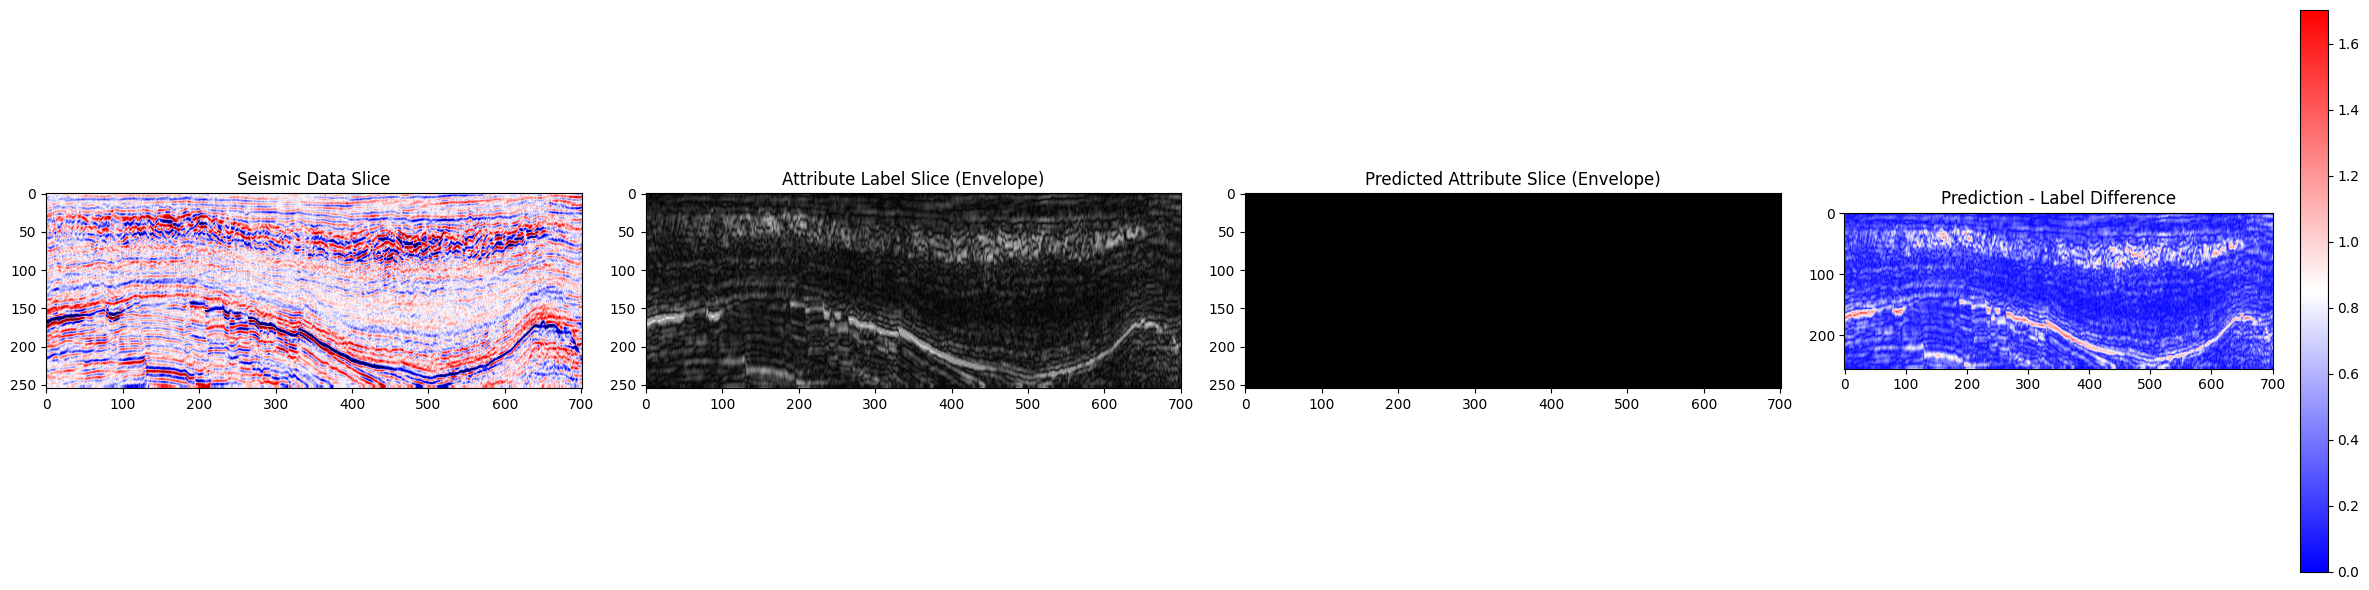

/tmp/ipykernel_2003/3105747928.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


In [14]:
index = 0
data = data_module.test_dataset[index][0][0,:,:]
label = test_y[index].cpu().numpy()  # type: ignore
prediction = predictions[index].cpu().numpy()  # type: ignore

fig = plot_data_label_prediction_slice(
    data=data,
    label=label,
    prediction=prediction,
)
fig.show()